In [2]:
import sys
sys.path.append('/home/nathan/thermo_flux')

import pandas as pd
import os
# Add the parent directory to sys.path
sys.path.append(os.path.abspath('../3_src/'))
# Now import Model from freeflux

import numpy as np

import seaborn as sns
import analysis.io_func as io_func
import matplotlib.pyplot as plt

from analysis import config_13c as config
import json
from cmap import Colormap

/home/nathan/PhD/04.Computational/202601_13C/3_src/freeflux/src/freeflux/core/reaction.py:104: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.substrates_info = pd.concat((self.substrates_info, newSubs))
/home/nathan/PhD/04.Computational/202601_13C/3_src/freeflux/src/freeflux/core/reaction.py:132: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.products_info = pd.concat((self.products_info, newPros))
/home/nathan/PhD/04.Computational/202601_13C/3_src/freeflux/src/freeflux/core/reaction.py:

###  i first scan through rxn common to my yeast model and y9 in preivous notebook 4c1. 
then here plot for reactions that have different directions

In [3]:
# Import general configs:
palette ,cpalette,cfg=io_func.import_plotconfigs(cpalette=True)

In [4]:
condition='WT' 
model=config.model
bootstrap_flux_dfwt=config.bootstrap_flux_df(condition)#pd.read_csv(f'{config.DRAWNSAMPLES_FOLDER}/{condition}_drawn_samples.csv',index_col=0)


In [5]:
condition='TM6' 
model=config.model
bootstrap_flux_dftm6=config.bootstrap_flux_df(condition)#pd.read_csv(f'{config.DRAWNSAMPLES_FOLDER}/{condition}_drawn_samples.csv',index_col=0)


In [6]:
def flux_of_metabolite(S_df, fluxes_df:pd.Series, MET:str,lb_abs=1e-1)->pd.DataFrame:
    """given the stoicheometry matrix, the flux dataframe for all reactions and the metabolite we look for 
        we get the values of fluxes that produce or consume this mets, 
        returns a dataframe with the fluxes values of the reactions that produce or consume the metabolite"""
    S_T_df = S_df.T
    ##MET_rxns_stoich is a series of reactions with how much of the metabolite is produced or consumed
    MET_rxns_stoich=S_T_df[MET]
    MET_rxns_stoich=MET_rxns_stoich[MET_rxns_stoich!=0] ##drop 0 values : rxn that dont produce or consume the metabolite
    #multiply fluxes values by the stoicheometry of the metabolite in the reaction
    df_met_flux=fluxes_df.loc[MET_rxns_stoich.index].mul(MET_rxns_stoich, axis=0)
    # drop low values
    df_met_flux=df_met_flux[abs(df_met_flux)>lb_abs] 
    return df_met_flux ##get the fluxes values of the reactions that produce or consume the metabolite


In [7]:
S_df=pd.read_csv(f'{config.INPUT_FOLDER}/ymodel_stoichiometric_matrix_df.csv',index_col=0)


In [13]:
met='atp_c'
df_vmet_wt=flux_of_metabolite(S_df,bootstrap_flux_dfwt.mean(axis=1),met)
df_vmet_tm6=flux_of_metabolite(S_df,bootstrap_flux_dftm6.mean(axis=1),met)
def filter_absthresh(df,abs_tresh=1.5):
    return df[abs(df)>abs_tresh]

dfplot=pd.concat([filter_absthresh(df_vmet_wt),filter_absthresh(df_vmet_tm6)],axis=1)
dfplot
# met='nadph_c'
# df_vmet_wt=flux_of_metabolite(S_df,full_flux_df[accepted_samples[0]],met)
# df_vmet_tm6=flux_of_metabolite(S_df,full_flux_dftm6[accepted_samplestm6[0]],met)
# def filter_absthresh(df,abs_tresh=0.2):
#     return df[abs(df)>abs_tresh]

# dfplot=pd.concat([filter_absthresh(df_vmet_wt),filter_absthresh(df_vmet_tm6)],axis=1)
# dfplot

,0,1
PC,-1.663483,NaN
HEX1,-15.267867,-3.792573
PFK,-14.101340,-2.863806
PGK,25.925184,4.903930
PYK,25.893048,5.080669
protein_reaction,-5.811195,-4.215990
storage_reaction,-1.784498,NaN
ATPASE,-5.981460,-15.672912
ADPATPtm-4-3,NaN,23.801419


In [15]:
##atp turnover rate ## having set met = atp _c in dfplot (turnover rate of atp)
dfatp_wt=dfplot[0]
print('max',-bootstrap_flux_dfwt.loc['PPCK',].max()*100/dfatp_wt[dfatp_wt<0].sum(),'min',-bootstrap_flux_dfwt.loc['PPCK'].min()*100/dfatp_wt[dfatp_wt<0].sum())
# dfatp_wt

max 1.7322867137849751 min 0.026652611232205154


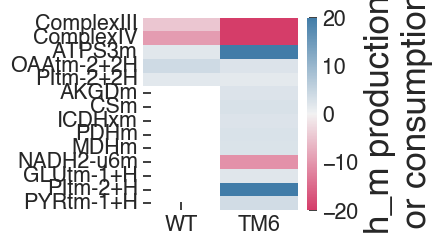

In [13]:
import colorsys
import matplotlib.ticker as ticker

fig,ax=plt.subplots(1,1,figsize=(2.5, 2.5))

##diverging cmap from cmap batlow
cm = Colormap('crameri:batlow')  
colors = cm(np.linspace(0, 1, 8))
# Get start and end colors from batlow
# start_color = 
low_color = colors[1][:3]   # RGB only, ignore alpha

# anchor high color (choose a real batlow endpoint instead of artificial inversion)
high_color = colors[-2][:3]   # or colors[-1][:3] if you want full extreme

# build diverging cmap
div_cmap = sns.diverging_palette(
    h_neg=0, h_pos=240,   # ignored effectively when as_cmap=True with custom colors
    as_cmap=True
)

hm=sns.heatmap(dfplot,cmap=div_cmap,ax=ax,vmin=-20,vmax=20,    center=0,
)
step = 1
ax.set_yticks(np.arange(0, len(dfplot), step)+0.5)
ax.set_yticklabels(dfplot.index[::step])

ax.set_xticklabels(['WT','TM6'])
# label colorbar
cbar = hm.collections[0].colorbar
cbar.set_label(f'{met} production\n or consumption')
##save
# plt.savefig(f'{config.SUPP_PLOTS_FOLDER}/SuppFig_{met}_fluxofmet_2conds.svg',dpi=300,bbox_inches='tight')